## Calculate the maximum energy needed for electron and protons

In [1]:
import os
import h5py
import numpy as np
import json

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import flash_amr_tools

import astropy.units as u
import astropy.constants as const

from synch_emission_functions import t_diff, t_accel, t_adv, tcool_proton, tcool_electron
# from synch_emission_functions import t_diff, t_adv, tcool_proton, tcool_electron, mp, Ekin

Some general quantities that are the sameL:

In [2]:

# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs

pe_arr = np.logspace(2, 7, 200)
print(
    f"Minimum & maximum of normalised momentum (electrons): {(pe_arr.min() * me * c**2).to(u.GeV):.5e}, {(pe_arr.max() * me * c**2).to(u.GeV):.5e}"
)

Minimum & maximum of normalised momentum (electrons): 5.10999e-02 GeV, 5.10999e+03 GeV


In [3]:
vwind = 2.7e3 * u.km / u.s

Parameters and constants for cosmic rays

In [4]:
# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs
mu = 1.4  # mean molecular weight


def mom(e):
    """Normalised momentum as function of energy."""
    return np.sqrt((e + 1) ** 2 - 1)

def ekin(p):
    """Normalised kinetic energy as a function of normalised momentum"""
    return np.sqrt(p**2 + 1) - 1

def dp_dekin(p):
    """Derivative of normalised momentum wrt normalised kinetic energy."""
    return 2 * (ekin(p) + 1) / p

#### Now calculate for vstar = 40km/s

In [5]:
ekin_arr = np.logspace(np.log10(0.5), 6, 500) * u.GeV

def mom_units(ekin, mass=mp):
    """Momentum in GeV/c"""
    return np.sqrt((ekin.cgs + mass*c**2)**2 - (mass*c**2)**2) / c

pp_arr = (mom_units(ekin_arr, mass=mp) / (mp * c)).to_value(u.dimensionless_unscaled)
pe_arr = (mom_units(ekin_arr, mass=me) / (me * c)).to_value(u.dimensionless_unscaled)


# take nominal values for the density and magnetic field at the shock
# this should be calcualted using the polar timeseries data and imported for each simulation type
# and take the mean value at the outer shock
rho_val = 4e-25 * u.g / u.cm**3
B_val = 10 * u.microgauss

# vstar = 40 * u.km/u.s

diff_10GeV = 3e25 * u.cm**2 * u.s**-1

In [6]:
bowshock_config_dict = json.load(open("../../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

bs_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"

<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff', 'ISM-v40-MHD']>
6.90183325693857e-25 g / cm3 1.9141267353006697e-06 G 36.80889935811361 km / s
5.9366328730308655e-25 g / cm3 1.8613850380269096e-06 G 37.1818291772932 km / s
7.637951268806611e-25 g / cm3 1.8828963876179236e-06 G 35.768473637898765 km / s
4.306143174610732e-25 g / cm3 8.650106951886743e-06 G 207.72964706098983 km / s


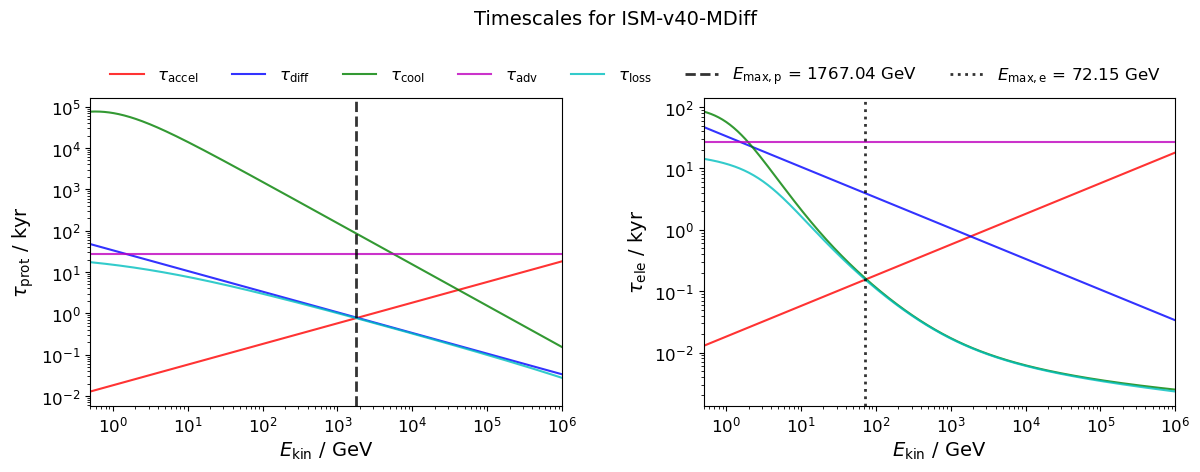

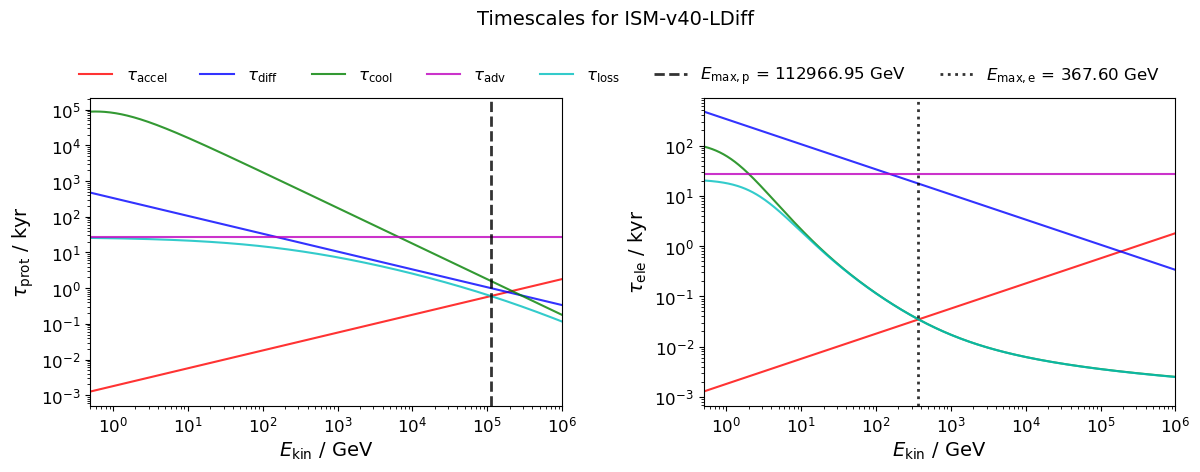

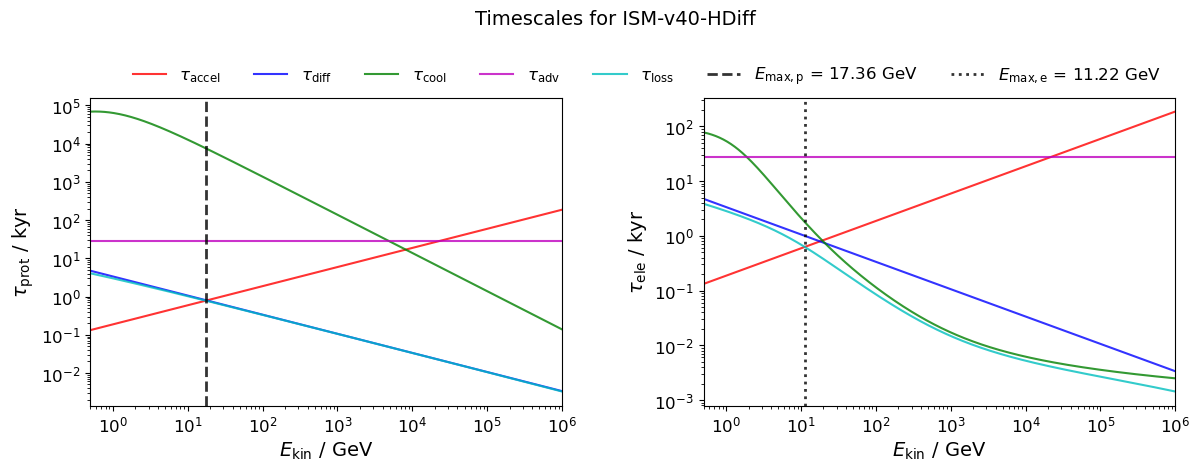

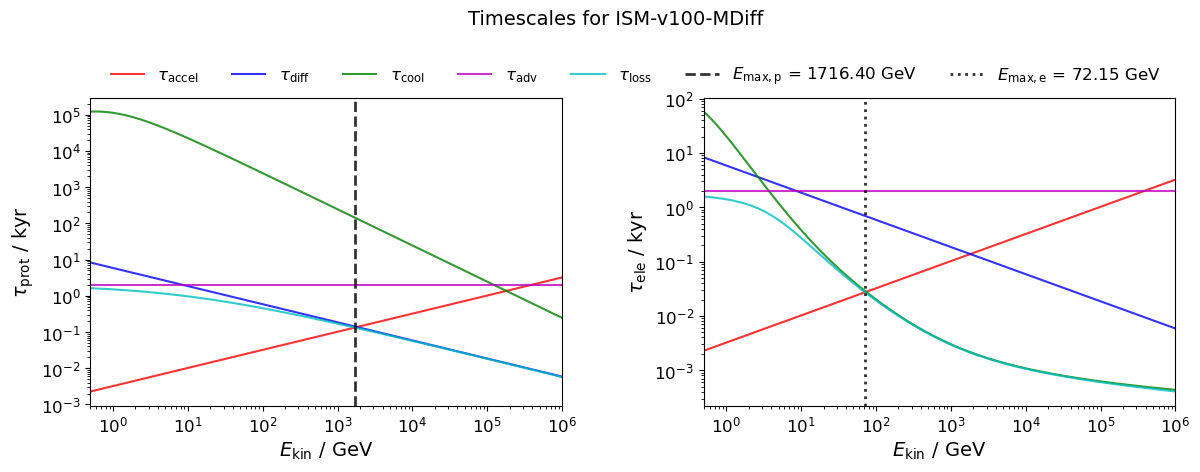

In [7]:
emax_prots = []
emax_electrs = []
file_to_read = f"../../data/polar_time_series_outer_revised.h5"
with h5py.File(file_to_read, "r") as f:

    print(f.keys())
    
    for ibs, bs_name in enumerate(bs_names):

        vstar = bowshock_config[bs_name]["vstar"] * u.km / u.s
        kappa_10 = bowshock_config[bs_name]["kappa_10"] * u.cm**2 / u.s

        dens_vals = f[bs_name]['dens'][()]
        mag_vals = f[bs_name]['mag'][()]
        vel_vals = f[bs_name]['vel'][()]
        rho_shock = np.mean(dens_vals[~np.isnan(dens_vals)]) * u.g / u.cm**3
        B_shock = np.mean(mag_vals[~np.isnan(mag_vals)]) * u.G
        vel_shock = np.mean(vel_vals[~np.isnan(vel_vals)]) * u.km/u.s
        print(rho_shock, B_shock, vel_shock)

        # claculate all times
        taccel_prot = t_accel(pp_arr, kappa_10, vel_shock, mass=mp).to(u.kyr)
        tdiff_prot = t_diff(pp_arr, vstar, kappa_10, mass=mp).to(u.kyr)
        tadv = t_adv(vel_shock, vstar).to(u.kyr)
        tcool_prot = tcool_proton(pp_arr, rho_shock).to(u.kyr)
        t_loss_prot = (1 / (1 / tcool_prot + 1 / tdiff_prot + 1 / tadv)).to(u.kyr)

        taccel_electr = t_accel(pe_arr, kappa_10, vel_shock, mass=me).to(u.kyr)
        tdiff_electr = t_diff(pe_arr, vstar, kappa_10, mass=me).to(u.kyr)
        tcool_electr = tcool_electron(pe_arr,  rho_shock, B_shock, Tstar=1e4 * u.K, vstar=vstar).to(u.kyr)
        t_loss_electr = (1 / (1 / tcool_electr + 1 / tdiff_electr + 1 / tadv)).to(u.kyr)

        fig, axs = plt.subplots(1,2,figsize=(14,4), gridspec_kw={'wspace':0.3})

        axs[0].plot(ekin_arr.to(u.GeV), taccel_prot, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), tdiff_prot, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), tcool_prot, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[0].plot(ekin_arr.to(u.GeV), t_loss_prot, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[0].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[0].set_ylabel(r"$\tau_\mathrm{prot}$ / kyr", fontsize=14)
        
        axs[1].plot(ekin_arr.to(u.GeV), taccel_electr, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), tdiff_electr, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), tcool_electr, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[1].plot(ekin_arr.to(u.GeV), t_loss_electr, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[1].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[1].set_ylabel(r"$\tau_\mathrm{ele}$ / kyr", fontsize=14)

        # finally find where taccel == tcool
        emax_prot = ekin_arr[np.argmin(np.abs(taccel_prot.value - t_loss_prot.value))]
        emax_electr = ekin_arr[np.argmin(np.abs(taccel_electr.value - t_loss_electr.value))]

        axs[0].axvline(emax_prot.to_value(u.GeV), label=rf'$E_\mathrm{{max}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0)
        axs[1].axvline(emax_electr.to_value(u.GeV), label=rf'$E_\mathrm{{max}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0)

        for ax in axs:
            ax.set_xlabel(r'$E_\mathrm{kin}$ / GeV', fontsize=14)
            ax.tick_params(axis='both', labelsize=12)
            ax.set_yscale('log')
            ax.set_xscale('log')
            ax.set_xlim(0.5, 1e6)

        
        fig.legend(
            handles=[
                mlines.Line2D([], [], label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, p}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, e}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0),
            ],
            fontsize=12,
            ncols=7,
            frameon=False,
            bbox_to_anchor=[0.9, 1.0]
        )

        fig.suptitle(f"Timescales for {bs_name}", fontsize=14, y=1.1)

        fig.savefig(f"{fig_dir}/maximal_energy_{bs_name}.pdf", dpi=200, bbox_inches='tight')
        
        # emax_prot = ekin_arr[np.argwhere(np.isclose(taccel_prot.value, tcool_prot.value))]
        # print(emax_prot)

        emax_prots.append(emax_prot.to_value(u.GeV))
        emax_electrs.append(emax_electr.to_value(u.GeV))

emax_electrs = np.array(emax_electrs)
emax_prots = np.array(emax_prots)


In [8]:
print("emax_prots =", emax_prots, " GeV")
print("emax_electrs =", emax_electrs, " GeV")

emax_prots = [1.76703606e+03 1.12966950e+05 1.73581081e+01 1.71639839e+03]  GeV
emax_electrs = [ 72.15074245 367.59570058  11.22257894  72.15074245]  GeV


In [9]:
pmax_prot = mom(emax_prots / (mp * c**2).to_value(u.GeV))
pmax_electr = mom(emax_electrs / (me * c**2).to_value(u.GeV))

print("pmax_prot =", pmax_prot, " / (mpc)")
print("pmax_electr =", pmax_electr, " / (mec)")

pmax_prot = [1.88428720e+03 1.20399924e+05 1.94744215e+01 1.83031812e+03]  / (mpc)
pmax_electr = [141196.48082877 719367.84131627  21963.03910703 141196.48082877]  / (mec)
